In [1]:
import uproot
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import particle
from particle import PDGID, Particle

In [128]:
tree = uproot.concatenate("/grid_mnt/data__data.polcms/cms/cuisset/ZHbbtautau/jobs/Zprime_Zh_Zbbhtautau_M600/Step_6/Ntuple_*.root:Events", 
                          filter_name=["luminosityBlock", "event", "GenPart_*", "Tau_*", "HLT_DoubleMediumChargedIsoPFTauHPS35_Trk1_eta2p1_Reg"])

In [112]:
tree = uproot.concatenate("/grid_mnt/data__data.polcms/cms/cuisset/ZHbbtautau/jobs/Zprime_Zh_Zbbhtautau_M600/Step_6/Ntuple_0.root:Events", 
                          filter_name=["luminosityBlock", "event", "GenPart_*", "Tau_*", "HLT_DoubleMediumChargedIsoPFTauHPS35_Trk1_eta2p1_Reg"])

In [107]:
full_tree = uproot.open("/grid_mnt/data__data.polcms/cms/cuisset/ZHbbtautau/jobs/Zprime_Zh_Zbbhtautau_M600/Step_6/Ntuple_0.root:Events")
sorted([ key for key in full_tree.keys() if key.startswith("HLT")])

['HLT_AK4CaloJet100',
 'HLT_AK4CaloJet120',
 'HLT_AK4CaloJet30',
 'HLT_AK4CaloJet40',
 'HLT_AK4CaloJet50',
 'HLT_AK4CaloJet80',
 'HLT_AK4PFJet100',
 'HLT_AK4PFJet120',
 'HLT_AK4PFJet30',
 'HLT_AK4PFJet50',
 'HLT_AK4PFJet80',
 'HLT_AK8PFHT750_TrimMass50',
 'HLT_AK8PFHT800_TrimMass50',
 'HLT_AK8PFHT850_TrimMass50',
 'HLT_AK8PFHT900_TrimMass50',
 'HLT_AK8PFJet140',
 'HLT_AK8PFJet15',
 'HLT_AK8PFJet200',
 'HLT_AK8PFJet25',
 'HLT_AK8PFJet260',
 'HLT_AK8PFJet320',
 'HLT_AK8PFJet330_TrimMass30_PFAK8BTagDeepCSV_p1',
 'HLT_AK8PFJet330_TrimMass30_PFAK8BTagDeepCSV_p17',
 'HLT_AK8PFJet330_TrimMass30_PFAK8BoostedDoubleB_np2',
 'HLT_AK8PFJet330_TrimMass30_PFAK8BoostedDoubleB_np4',
 'HLT_AK8PFJet330_TrimMass30_PFAK8BoostedDoubleB_p02',
 'HLT_AK8PFJet360_TrimMass30',
 'HLT_AK8PFJet380_TrimMass30',
 'HLT_AK8PFJet40',
 'HLT_AK8PFJet400',
 'HLT_AK8PFJet400_TrimMass30',
 'HLT_AK8PFJet420_TrimMass30',
 'HLT_AK8PFJet450',
 'HLT_AK8PFJet500',
 'HLT_AK8PFJet550',
 'HLT_AK8PFJet60',
 'HLT_AK8PFJet80',
 'HLT_AK

In [82]:
tree[["luminosityBlock", "event"]]

<Array [{luminosityBlock: 1, ...}, ..., {...}] type='1000 * {luminosityBloc...'>

In [129]:
gen = ak.zip({key:tree[key] for key in tree.fields if key.startswith("GenPart_")} | {"GenPart_id":ak.local_index(tree.GenPart_eta)})
gen

<Array [[{GenPart_eta: ..., ...}, ...], ...] type='50000 * var * {GenPart_e...'>

In [130]:
tau_reco = ak.zip({key:tree[key] for key in tree.fields if key.startswith("Tau_")} | {"Tau_id":ak.local_index(tree.Tau_eta)}) 
zipped_tree = ak.zip({"Tau" : tau_reco, "Gen" : gen, "event" : tree.event, "luminosityBlock" : tree.luminosityBlock, "HLT_DoubleMediumChargedIsoPFTauHPS35_Trk1_eta2p1_Reg":tree["HLT_DoubleMediumChargedIsoPFTauHPS35_Trk1_eta2p1_Reg"]}, depth_limit=1)
zipped_tree

<Array [{Tau: [...], Gen: [...], ...}, ...] type='50000 * {Tau: var * {Tau_...'>

# Lepton filters

## Gen information

In [131]:
# plot zprime mass
def boolFilterDecayByPdg(parent_pdgid, zprime_child_pdg):
    return (gen.GenPart_pdgId[gen.GenPart_genPartIdxMother] == parent_pdgid) & (gen.GenPart_pdgId == zprime_child_pdg)
def filterDecayByPdg(parent_pdgid, zprime_child_pdg):
    return gen[boolFilterDecayByPdg(parent_pdgid, zprime_child_pdg)]
def getParticleDaughters(parent):
    return gen[gen.GenPart_genPartIdxMother == parent.GenPart_id]
def applyMapToAk(fct, array):
    counts = ak.num(array)
    flat = ak.flatten(array)
    flat_mapped = np.vectorize(fct)(flat)
    return ak.unflatten(flat_mapped, counts)
def isHadron(pdgs):
    return applyMapToAk(lambda pdg:PDGID(pdg).is_hadron, pdgs)
def selectHadronicTaus(tau_array):
    return ak.any(isHadron(getParticleDaughters(tau_array).GenPart_pdgId), axis=-1)

In [132]:
tau_plus = filterDecayByPdg(Particle.from_name("H0").pdgid, Particle.from_name("tau+").pdgid)[:, 0]
tau_minus = filterDecayByPdg(Particle.from_name("H0").pdgid, Particle.from_name("tau-").pdgid)[:, 0]
ditau_hadronic = selectHadronicTaus(tau_plus) & selectHadronicTaus(tau_minus)

### Tau gen PT

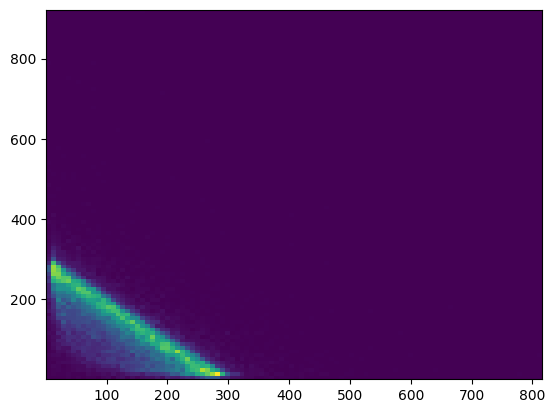

In [133]:
plt.hist2d(np.array(tau_plus.GenPart_pt),np.array( tau_minus.GenPart_pt), bins=100)
None

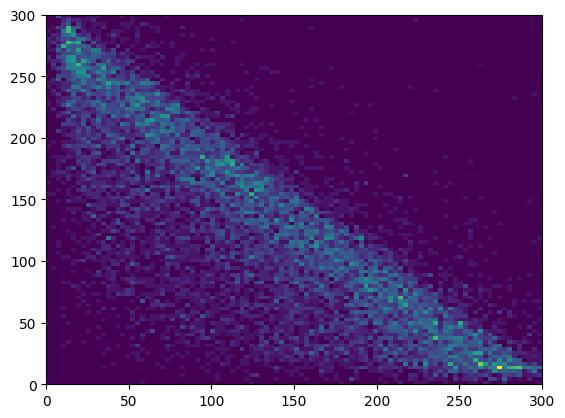

In [134]:
plt.hist2d(np.array(tau_plus[ditau_hadronic].GenPart_pt),np.array( tau_minus[ditau_hadronic].GenPart_pt), bins=100, range=[[0, 300]]*2)
None

### Tau reco study

In [135]:
ditau_reco = (ak.num(zipped_tree.Tau.Tau_eta) >= 2)
ditau_reco

<Array [True, True, False, True, ..., False, True, False] type='50000 * bool'>

Text(0.5, 1.0, 'RECO Tau1 vs Tau2 pt')

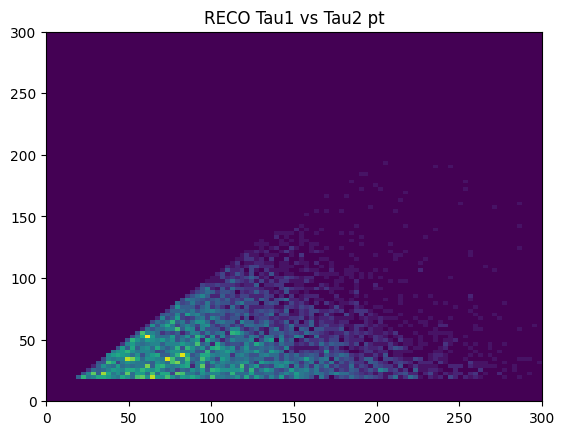

In [136]:
plt.hist2d(np.array(zipped_tree[ditau_hadronic & ditau_reco].Tau.Tau_pt[:, 0]),np.array(zipped_tree[ditau_hadronic & ditau_reco].Tau.Tau_pt[:, 1]), bins=100, range=[[0, 300]]*2)
plt.title("RECO Tau1 vs Tau2 pt")

In [137]:

tautau_trigger = (ak.fill_none(ak.pad_none(zipped_tree.Tau.Tau_pt, 2, clip=True)[:, 0] >= 40., False) 
                  & ak.fill_none(ak.pad_none(zipped_tree.Tau.Tau_pt, 2, clip=True)[:, 1] >= 40., False) 
                  & ak.fill_none(ak.pad_none(zipped_tree.Tau.Tau_eta, 2, clip=True)[:, 0] <= 2.1, False)
                  & ak.fill_none(ak.pad_none(zipped_tree.Tau.Tau_eta, 2, clip=True)[:, 1] <= 2.1, False)
)
tautau_trigger

<Array [False, True, False, False, ..., False, True, False] type='50000 * bool'>

In [138]:
zipped_tree[ditau_hadronic & ditau_reco & tautau_trigger]

<Array [{Tau: [...], Gen: [...], ...}, ...] type='3848 * {Tau: var * {Tau_c...'>

In [139]:
print("||".join([f"(event == {row.event} && luminosityBlock == {row.luminosityBlock})" for row in zipped_tree[ditau_hadronic & ditau_reco & tautau_trigger][["event", "luminosityBlock"]]]))

(event == 20 && luminosityBlock == 1)||(event == 32 && luminosityBlock == 1)||(event == 30 && luminosityBlock == 1)||(event == 65 && luminosityBlock == 1)||(event == 75 && luminosityBlock == 1)||(event == 107 && luminosityBlock == 1)||(event == 135 && luminosityBlock == 1)||(event == 166 && luminosityBlock == 1)||(event == 175 && luminosityBlock == 1)||(event == 195 && luminosityBlock == 1)||(event == 200 && luminosityBlock == 1)||(event == 211 && luminosityBlock == 1)||(event == 207 && luminosityBlock == 1)||(event == 225 && luminosityBlock == 1)||(event == 234 && luminosityBlock == 1)||(event == 270 && luminosityBlock == 1)||(event == 310 && luminosityBlock == 2)||(event == 360 && luminosityBlock == 2)||(event == 399 && luminosityBlock == 2)||(event == 406 && luminosityBlock == 2)||(event == 417 && luminosityBlock == 2)||(event == 439 && luminosityBlock == 2)||(event == 433 && luminosityBlock == 2)||(event == 451 && luminosityBlock == 2)||(event == 438 && luminosityBlock == 2)||(even

Text(0.5, 1.0, 'RECO Tau1 vs Tau2 pt')

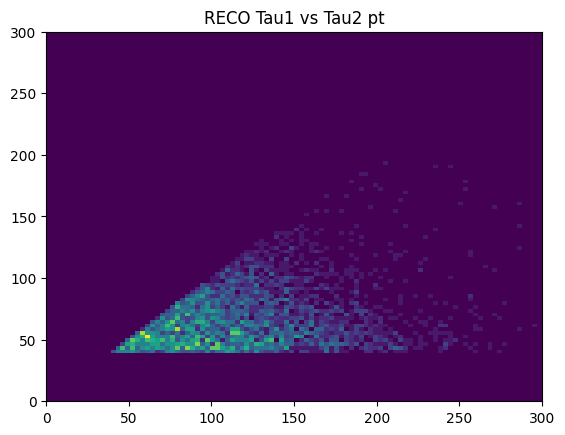

In [140]:
plt.hist2d(np.array(zipped_tree[ditau_hadronic & ditau_reco & tautau_trigger].Tau.Tau_pt[:, 0]),np.array(zipped_tree[ditau_hadronic & ditau_reco & tautau_trigger].Tau.Tau_pt[:, 1]), bins=100, range=[[0, 300]]*2)
plt.title("RECO Tau1 vs Tau2 pt")

### HLT

In [141]:
hlt_path = zipped_tree.HLT_DoubleMediumChargedIsoPFTauHPS35_Trk1_eta2p1_Reg

In [151]:
len(zipped_tree[hlt_path&ditau_hadronic])/len(zipped_tree[ditau_hadronic])

0.23102560218148765

In [145]:
zipped_tree[ditau_hadronic & ditau_reco & tautau_trigger & hlt_path]

<Array [{Tau: [...], Gen: [...], ...}, ...] type='2119 * {Tau: var * {Tau_c...'>

### Tau gen decay study

In [44]:
pdgs, counts = np.unique(ak.flatten(gen.GenPart_pdgId), return_counts=True)
pdgs = list(map(PDGID, list(pdgs)))
pdgs

[<PDGID: -20433>,
 <PDGID: -5232>,
 <PDGID: -5224>,
 <PDGID: -5214>,
 <PDGID: -5122>,
 <PDGID: -4232>,
 <PDGID: -4222>,
 <PDGID: -4212>,
 <PDGID: -4122>,
 <PDGID: -533>,
 <PDGID: -531>,
 <PDGID: -523>,
 <PDGID: -521>,
 <PDGID: -513>,
 <PDGID: -511>,
 <PDGID: -433>,
 <PDGID: -431>,
 <PDGID: -423>,
 <PDGID: -421>,
 <PDGID: -413>,
 <PDGID: -411>,
 <PDGID: -311>,
 <PDGID: -211>,
 <PDGID: -16>,
 <PDGID: -15>,
 <PDGID: -14>,
 <PDGID: -13>,
 <PDGID: -12>,
 <PDGID: -11>,
 <PDGID: -5>,
 <PDGID: -4>,
 <PDGID: -3>,
 <PDGID: -2>,
 <PDGID: -1>,
 <PDGID: 1>,
 <PDGID: 2>,
 <PDGID: 3>,
 <PDGID: 4>,
 <PDGID: 5>,
 <PDGID: 11>,
 <PDGID: 12>,
 <PDGID: 13>,
 <PDGID: 14>,
 <PDGID: 15>,
 <PDGID: 16>,
 <PDGID: 21>,
 <PDGID: 22>,
 <PDGID: 23>,
 <PDGID: 25>,
 <PDGID: 111>,
 <PDGID: 130>,
 <PDGID: 211>,
 <PDGID: 221>,
 <PDGID: 223>,
 <PDGID: 310>,
 <PDGID: 311>,
 <PDGID: 321>,
 <PDGID: 331>,
 <PDGID: 411>,
 <PDGID: 413>,
 <PDGID: 415>,
 <PDGID: 421>,
 <PDGID: 423>,
 <PDGID: 431>,
 <PDGID: 433>,
 <PDGID: 441>,
 <

In [38]:
y=pdgs[50]
y

<PDGID: 130>

In [45]:
for pdgid in pdgs:
    try:
        print(Particle.from_pdgid(pdgid))
    except:
        pass

D(s1)(2460)-
Xi(b)~0
Sigma(b)*~-
Lambda(b)~0
Xi(c)~-
Sigma(c)(2455)~--
Sigma(c)(2455)~-
Lambda(c)~-
B(s)*~0
B(s)~0
B*-
B-
B*~0
B~0
D(s)*-
D(s)-
D*(2007)~0
D~0
D*(2010)-
D-
K~0
pi-
nu(tau)~
tau+
nu(mu)~
mu+
nu(e)~
e+
b~
c~
s~
u~
d~
d
u
s
c
b
e-
nu(e)
mu-
nu(mu)
tau-
nu(tau)
g
gamma
Z0
H0
pi0
K(L)0
pi+
eta
omega(782)
K(S)0
K0
K+
eta'(958)
D+
D*(2010)+
D(2)*(2460)+
D0
D*(2007)0
D(s)+
D(s)*+
eta(c)(1S)
J/psi(1S)
chi(c2)(1P)
B0
B*0
B+
B*+
B(s)0
B(s)*0
(ud)(0)
(ud)(1)
(uu)(1)
Lambda(c)+
Sigma(c)(2520)++
Xi(c)+
Sigma(b)-
Sigma(b)*-
Lambda(b)0
Sigma(b)+
Sigma(b)*+


In [ ]:

plt.hist(pdgs[np.abs(pdgs) < 10000], bins)

In [63]:
filterDecayByPdg(9000001, Particle.from_name("Z0").pdgid)

<Array [{GenPart_eta: [-0.625], ...}, ...] type='100 * {GenPart_eta: var * ...'>

In [67]:
tau_decays = ak.flatten(gen[(gen.GenPart_pdgId[gen.GenPart_genPartIdxMother] == Particle.from_name("tau+").pdgid)].GenPart_pdgId)
for pdgid in tau_decays:
    try:
        print(Particle.from_pdgid(pdgid))
    except:
        pass

tau+
nu(tau)~
pi0
pi+
tau+
gamma
nu(tau)~
pi+
tau+
nu(tau)~
pi+
tau+
nu(tau)~
pi0
pi+
nu(tau)~
pi0
pi+
nu(tau)~
pi0
pi+
nu(tau)~
pi+
pi+
pi-
tau+
gamma
nu(tau)~
pi+
pi+
pi-
tau+
nu(tau)~
pi+
nu(tau)~
pi0
pi0
pi+
tau+
nu(tau)~
pi+
pi+
pi-
nu(tau)~
pi+
pi+
pi-
nu(tau)~
pi+
pi+
pi-
nu(tau)~
pi0
pi+
nu(tau)~
mu+
nu(mu)
nu(tau)~
pi0
pi0
pi+
nu(tau)~
pi0
pi+
nu(tau)~
pi0
pi+
nu(tau)~
mu+
nu(mu)
nu(tau)~
e+
nu(e)
nu(tau)~
mu+
nu(mu)
nu(tau)~
pi+
tau+
gamma
nu(tau)~
pi0
pi+
pi+
pi-
tau+
gamma
nu(tau)~
pi+
pi+
pi-
tau+
gamma
nu(tau)~
e+
nu(e)
tau+
gamma
nu(tau)~
pi0
pi+
nu(tau)~
pi0
pi+
pi+
pi-
tau+
nu(tau)~
pi+
nu(tau)~
pi0
pi0
pi+
nu(tau)~
pi+
nu(tau)~
pi0
pi+
nu(tau)~
pi0
pi+
nu(tau)~
pi+
pi+
pi-
tau+
gamma
nu(tau)~
pi0
pi0
pi0
pi+
tau+
gamma
nu(tau)~
e+
nu(e)
nu(tau)~
mu+
nu(mu)
tau+
gamma
nu(tau)~
pi+
nu(tau)~
e+
nu(e)
tau+
nu(tau)~
mu+
nu(mu)
nu(tau)~
pi+
pi+
pi-
tau+
gamma
nu(tau)~
pi0
pi+
K0
nu(tau)~
mu+
nu(mu)
nu(tau)~
e+
nu(e)
nu(tau)~
pi0
pi0
pi+
tau+
nu(tau)~
pi0
pi+
tau+
gamma
nu(t